# STEP 4 — Plot paper-style thermal stress UTCImax Jawa (1996–2025)
Menghasilkan peta *smooth* beresolusi tinggi dan kurva time series dari hasil STEP 3, dengan susunan multi-panel bergaya jurnal.

**Metodologi penting:** interpolasi linear + *native grid footprint* + clipping poligon Jawa hanya dipakai pada **gambar**. Semua hitungan kategori dan nilai klimatologi tetap dari grid asli. Aktifkan `DISPLAY_RENDER='native'` di helper untuk membandingkan peta pada resolusi data asli.

**Hasil:** time series kategori, 8 panel peta spasial, komparasi kategori panas, UTCI mean/max time series, peta fokus ≥32/≥38 °C.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

OUT_DIR=Path(r"D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025")
ANNUAL_FILE=OUT_DIR/'06_utci_thermal_stress_annual_1996_2025.nc'
MASK_FILE=OUT_DIR/'00_Jawa_mask_native_grid.nc'
PLOT_DIR=OUT_DIR/'Plot_UTCI_Jawa_PaperStyle'
PLOT_DIR.mkdir(parents=True,exist_ok=True)
if not ANNUAL_FILE.exists():raise FileNotFoundError(f'Jalankan STEP 3: {ANNUAL_FILE}')
if not MASK_FILE.exists():raise FileNotFoundError(f'Jalankan STEP 2: {MASK_FILE}')
with xr.open_dataset(ANNUAL_FILE,decode_timedelta=False) as ds:
    years=np.asarray(ds.year.values,dtype=int)
    lat=np.asarray(ds.latitude.values,float);lon=np.asarray(ds.longitude.values,float)
    all_data={key:np.asarray(ds[key].values,float) for key in ds.data_vars}
with xr.open_dataset(MASK_FILE,decode_timedelta=False) as mds:
    valid_mask=np.asarray(mds.java_mask.values,bool)
if valid_mask.shape!=(len(lat),len(lon)):
    raise ValueError('Mask STEP 2 dan annual STEP 3 memiliki bentuk grid berbeda.')
print('Years:',years.min(),years.max(), '| map shape:',valid_mask.shape,'| valid grids:',valid_mask.sum())

Years: 1996 2025 | map shape: (12, 36) | valid grids: 176


## 1. Plotting helpers — interpolasi hanya untuk visual, tidak untuk analisis

In [2]:
# === HELPER PETA JAWA: STYLE JURNAL + SMOOTH DISPLAY-ONLY ===
import warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.interpolate import griddata, RegularGridInterpolator
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
from shapely.ops import unary_union
try:
    from shapely import contains_xy
except ImportError:
    from shapely.vectorized import contains as contains_xy

MAP_EXTENT=(104.5,116.5,-9.2,-5.0)
DISPLAY_RENDER='smooth'    # 'smooth' atau 'native'; tidak memengaruhi hasil perhitungan
DISPLAY_NX,DISPLAY_NY=650,260
FIG_DPI=350
SAVE_PDF=True
SHAPEFILE_ADMIN1=None   # boleh diisi path shapefile Natural Earth 10m lokal
mpl.rcParams.update({'font.family':'serif','font.serif':['DejaVu Serif'],
  'font.size':9,'axes.titlesize':10,'axes.labelsize':9,'xtick.labelsize':8,
  'ytick.labelsize':8,'figure.titlesize':13,'axes.linewidth':0.8,
  'savefig.facecolor':'white','figure.facecolor':'white'})

def java_records():
    try:
        shp=Path(SHAPEFILE_ADMIN1) if SHAPEFILE_ADMIN1 else shpreader.natural_earth(
            resolution='10m',category='cultural',name='admin_1_states_provinces')
        recs=[]
        for rec in shpreader.Reader(shp).records():
            attr=rec.attributes
            country=' '.join(str(attr.get(k,'')).lower() for k in ('admin','geonunit','name_en','name'))
            label=' '.join(str(attr.get(k,'')).lower() for k in ('name','name_en','name_local','gn_name'))
            if 'indonesia' in country and any(s in label for s in ('jawa','java','jakarta','djakarta','yogyakarta','banten')):
                recs.append(rec)
        if not recs: warnings.warn('Poligon admin1 Jawa tidak ditemukan; pakai mask grid.')
        return recs
    except Exception as exc:
        warnings.warn(f'Natural Earth tidak tersedia ({exc}); peta masih memakai native mask.')
        return []

JAVA_RECORDS=java_records()
JAVA_GEOMS=[r.geometry for r in JAVA_RECORDS]
JAVA_POLYGON=unary_union(JAVA_GEOMS) if JAVA_GEOMS else None
_FINE_CACHE={}

def smooth_field(field,lat,lon,valid_mask):
    z=np.asarray(field,dtype=float).copy();z[~valid_mask]=np.nan
    iy=np.argsort(lat);ix=np.argsort(lon)
    slat=np.asarray(lat)[iy];slon=np.asarray(lon)[ix]
    sz=z[np.ix_(iy,ix)]
    if np.any(np.diff(slat)<=0) or np.any(np.diff(slon)<=0):
        raise ValueError('Latitude/longitude duplikat atau tidak monoton.')
    good=np.isfinite(sz)
    if good.sum()<3:return slon,slat,np.ma.masked_invalid(sz)
    key=(tuple(MAP_EXTENT),DISPLAY_NX,DISPLAY_NY)
    if key not in _FINE_CACHE:
        fx=np.linspace(MAP_EXTENT[0],MAP_EXTENT[1],DISPLAY_NX)
        fy=np.linspace(MAP_EXTENT[2],MAP_EXTENT[3],DISPLAY_NY)
        fxx,fyy=np.meshgrid(fx,fy)
        inside=np.asarray(contains_xy(JAVA_POLYGON,fxx,fyy),dtype=bool) if JAVA_POLYGON is not None else np.ones(fxx.shape,bool)
        _FINE_CACHE[key]=(fx,fy,fxx,fyy,inside)
    fx,fy,fxx,fyy,inside=_FINE_CACHE[key]
    gx,gy=np.meshgrid(slon,slat)
    pts=np.column_stack((gx[good],gy[good]))
    dense=griddata(pts,sz[good],(fxx,fyy),method='linear')
    missing=inside & ~np.isfinite(dense)
    if missing.any():
        nn=griddata(pts,sz[good],(fxx,fyy),method='nearest')
        dense[missing]=nn[missing]
    footprint=RegularGridInterpolator((slat,slon),good.astype('float32'),method='nearest',bounds_error=False,fill_value=0)
    supported=footprint(np.column_stack((fyy.ravel(),fxx.ravel()))).reshape(fxx.shape)>0.5
    dense[~(inside & supported)]=np.nan
    return fx,fy,np.ma.masked_invalid(dense)

def draw_field(ax,field,lat,lon,valid_mask,cmap='YlOrRd',vmin=None,vmax=None):
    cmap_obj=mpl.colormaps[cmap].copy();cmap_obj.set_bad((1,1,1,0))
    if DISPLAY_RENDER=='smooth':
        xx,yy,z=smooth_field(field,lat,lon,valid_mask)
    elif DISPLAY_RENDER=='native':
        xx,yy=lon,lat;z=np.ma.masked_invalid(np.where(valid_mask,field,np.nan))
    else:raise ValueError('DISPLAY_RENDER = smooth atau native')
    return ax.pcolormesh(xx,yy,z,cmap=cmap_obj,vmin=vmin,vmax=vmax,
                         shading='auto',transform=ccrs.PlateCarree(),rasterized=True,zorder=2)

def setup_map(ax,left=True,bottom=True):
    ax.set_extent(MAP_EXTENT,crs=ccrs.PlateCarree())
    # Batas pulau dan provinsi berasal dari JAVA_GEOMS; hindari coastal download late pada savefig.
    for g in JAVA_GEOMS:
        ax.add_geometries([g],crs=ccrs.PlateCarree(),facecolor='none',edgecolor='0.23',linewidth=0.44,zorder=7)
    gl=ax.gridlines(draw_labels=True,linewidth=0.30,linestyle=':',alpha=0.40,x_inline=False,y_inline=False)
    gl.top_labels=False;gl.right_labels=False;gl.left_labels=left;gl.bottom_labels=bottom
    gl.xlabel_style={'size':7};gl.ylabel_style={'size':7}

def robust_limits(fields,p_low=2,p_high=98,zero_floor=False):
    parts=[np.asarray(a,dtype=float) for a in fields]
    vals=np.concatenate([a[np.isfinite(a)] for a in parts if np.isfinite(a).any()]) if any(np.isfinite(a).any() for a in parts) else np.array([0.,1.])
    lo,hi=np.percentile(vals,[p_low,p_high]).astype(float)
    if zero_floor:lo=0.0
    if not hi>lo:hi=lo+max(1.,abs(lo)*0.02)
    return float(lo),float(hi)

def area_mean(field,lat,mask):
    w=np.cos(np.deg2rad(lat))[:,None]*np.ones((1,field.shape[-1]))
    m=np.isfinite(field)&mask
    return float(np.sum(field[m]*w[m])/w[m].sum()) if m.any() else np.nan

def save_fig(fig,name,plot_dir):
    png=plot_dir/f'{name}.png'
    fig.savefig(png,dpi=FIG_DPI,bbox_inches='tight',facecolor='white')
    if SAVE_PDF:fig.savefig(plot_dir/f'{name}.pdf',bbox_inches='tight',facecolor='white')
    plt.show();plt.close(fig)
    print('Disimpan:',png)

## 2. FIG 01 — time series annual heat stress (8 indikator)

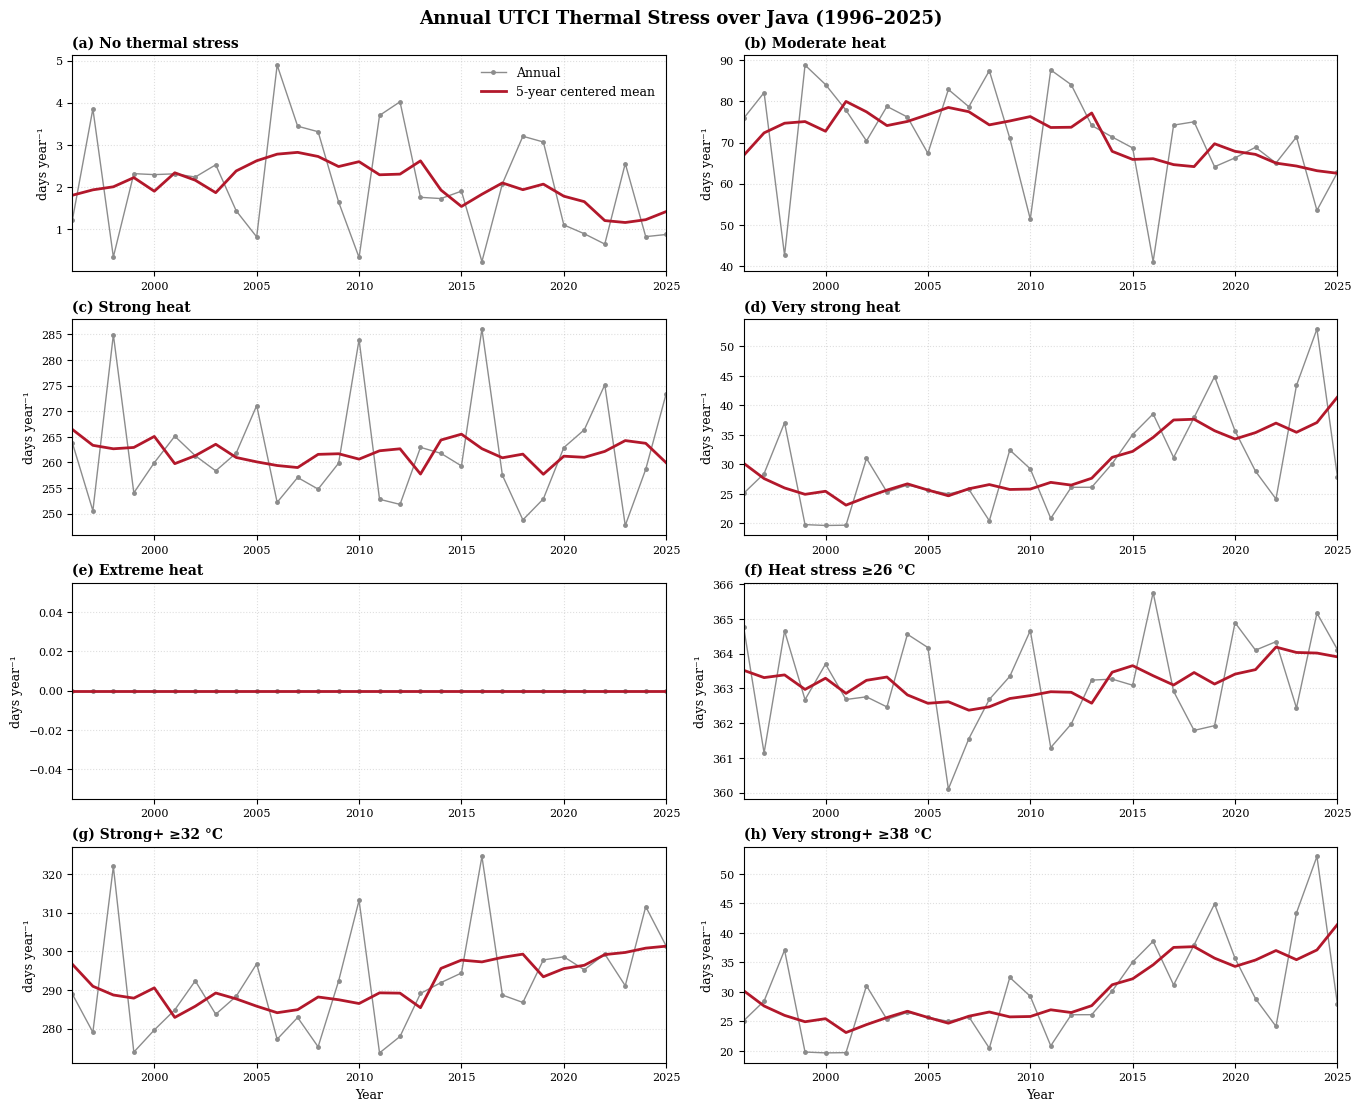

Disimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\Plot_UTCI_Jawa_PaperStyle\FIG01_UTCI_Jawa_ThermalStress_TimeSeries.png


In [3]:
spec=[('NTS_days','No thermal stress','days year⁻¹'),('MHS_days','Moderate heat','days year⁻¹'),
      ('SHS_days','Strong heat','days year⁻¹'),('VSHS_days','Very strong heat','days year⁻¹'),
      ('EHS_days','Extreme heat','days year⁻¹'),('HeatStress_days','Heat stress ≥26 °C','days year⁻¹'),
      ('StrongPlus_days','Strong+ ≥32 °C','days year⁻¹'),('VeryStrongPlus_days','Very strong+ ≥38 °C','days year⁻¹')]
fig,axs=plt.subplots(4,2,figsize=(13.5,11),constrained_layout=True)
regional={}
for i,(key,title,ylabel) in enumerate(spec):
    ax=axs.flat[i];y=np.array([area_mean(field,lat,valid_mask) for field in all_data[key]])
    regional[key]=y
    ax.plot(years,y,'o-',color='0.55',ms=2.5,lw=1,label='Annual')
    ax.plot(years,pd.Series(y).rolling(5,center=True,min_periods=3).mean(),color='#b2182b',lw=2,label='5-year centered mean')
    ax.set_title(f'({chr(97+i)}) {title}',loc='left',weight='bold');ax.set_ylabel(ylabel)
    ax.set_xlim(years.min(),years.max());ax.grid(ls=':',alpha=.4)
    if i>=6:ax.set_xlabel('Year')
axs.flat[0].legend(frameon=False)
fig.suptitle('Annual UTCI Thermal Stress over Java (1996–2025)',weight='bold')
save_fig(fig,'FIG01_UTCI_Jawa_ThermalStress_TimeSeries',PLOT_DIR)

## 3. FIG 02 — 8 peta spasial multi-panel yang sudah smooth

C:\Users\User\AppData\Local\Temp\ipykernel_3804\207601538.py:4: RuntimeWarning: Mean of empty slice
  z=np.nanmean(all_data[key],axis=0)
C:\Users\User\AppData\Local\Temp\ipykernel_3804\207601538.py:4: RuntimeWarning: Mean of empty slice
  z=np.nanmean(all_data[key],axis=0)
C:\Users\User\AppData\Local\Temp\ipykernel_3804\207601538.py:4: RuntimeWarning: Mean of empty slice
  z=np.nanmean(all_data[key],axis=0)
C:\Users\User\AppData\Local\Temp\ipykernel_3804\207601538.py:4: RuntimeWarning: Mean of empty slice
  z=np.nanmean(all_data[key],axis=0)
C:\Users\User\AppData\Local\Temp\ipykernel_3804\207601538.py:4: RuntimeWarning: Mean of empty slice
  z=np.nanmean(all_data[key],axis=0)
C:\Users\User\AppData\Local\Temp\ipykernel_3804\207601538.py:4: RuntimeWarning: Mean of empty slice
  z=np.nanmean(all_data[key],axis=0)
C:\Users\User\AppData\Local\Temp\ipykernel_3804\207601538.py:4: RuntimeWarning: Mean of empty slice
  z=np.nanmean(all_data[key],axis=0)
C:\Users\User\AppData\Local\Temp\ipykerne

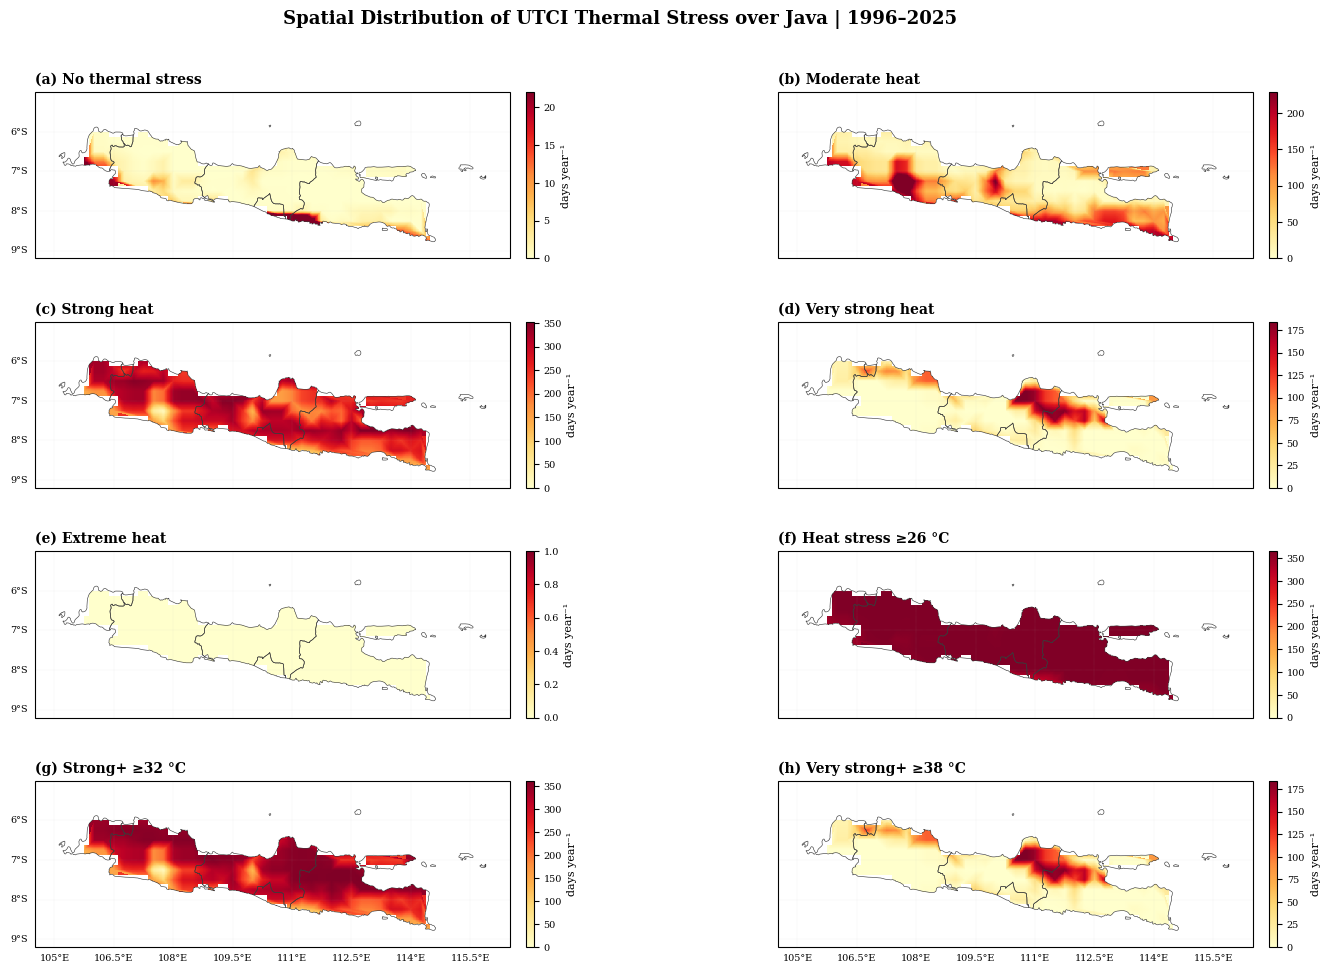

Disimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\Plot_UTCI_Jawa_PaperStyle\FIG02_UTCI_Jawa_ThermalStress_Spatial_SMOOTH.png


In [4]:
fig=plt.figure(figsize=(15.6,10.3));gs=fig.add_gridspec(4,2,wspace=.18,hspace=.38,left=.05,right=.93,bottom=.07,top=.9)
for i,(key,title,_) in enumerate(spec):
    ax=fig.add_subplot(gs[i//2,i%2],projection=ccrs.PlateCarree())
    z=np.nanmean(all_data[key],axis=0)
    vmin,vmax=robust_limits([z],zero_floor=True)
    m=draw_field(ax,z,lat,lon,valid_mask,cmap='YlOrRd',vmin=vmin,vmax=vmax)
    setup_map(ax,left=i%2==0,bottom=i>=6)
    ax.set_title(f'({chr(97+i)}) {title}',loc='left',weight='bold')
    cb=fig.colorbar(m,ax=ax,orientation='vertical',fraction=.035,pad=.025)
    cb.ax.tick_params(labelsize=7);cb.set_label('days year⁻¹',fontsize=8)
fig.suptitle('Spatial Distribution of UTCI Thermal Stress over Java | 1996–2025',weight='bold')
save_fig(fig,'FIG02_UTCI_Jawa_ThermalStress_Spatial_SMOOTH',PLOT_DIR)

## 4. FIG 03 — kategori eksklusif moderate / strong / very strong

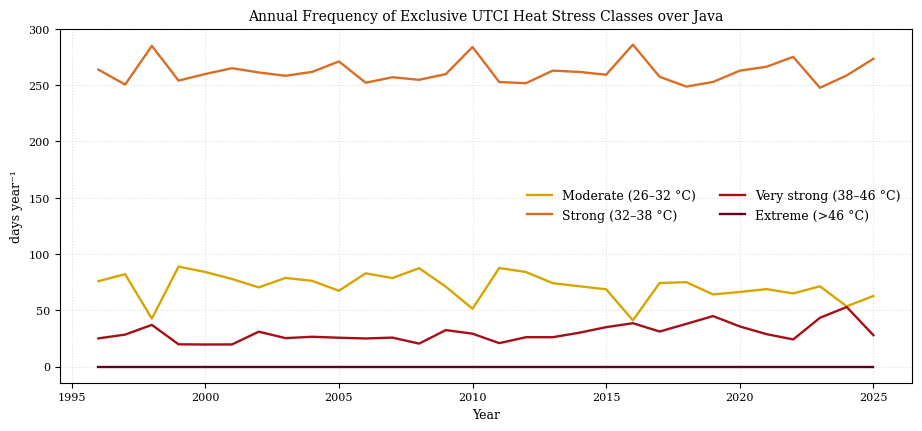

Disimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\Plot_UTCI_Jawa_PaperStyle\FIG03_UTCI_Jawa_Exclusive_HeatStress_Comparison.png


In [5]:
fig,ax=plt.subplots(figsize=(11,4.6))
for key,label,col in [('MHS_days','Moderate (26–32 °C)','#d8a500'),('SHS_days','Strong (32–38 °C)','#db6d23'),
                      ('VSHS_days','Very strong (38–46 °C)','#a50f15'),('EHS_days','Extreme (>46 °C)','#620021')]:
    ax.plot(years,regional[key],label=label,lw=1.7,color=col)
ax.set(xlabel='Year',ylabel='days year⁻¹',title='Annual Frequency of Exclusive UTCI Heat Stress Classes over Java')
ax.grid(ls=':',alpha=.4);ax.legend(frameon=False,ncol=2)
save_fig(fig,'FIG03_UTCI_Jawa_Exclusive_HeatStress_Comparison',PLOT_DIR)

## 5. FIG 04 — UTCI annual mean dan maximum

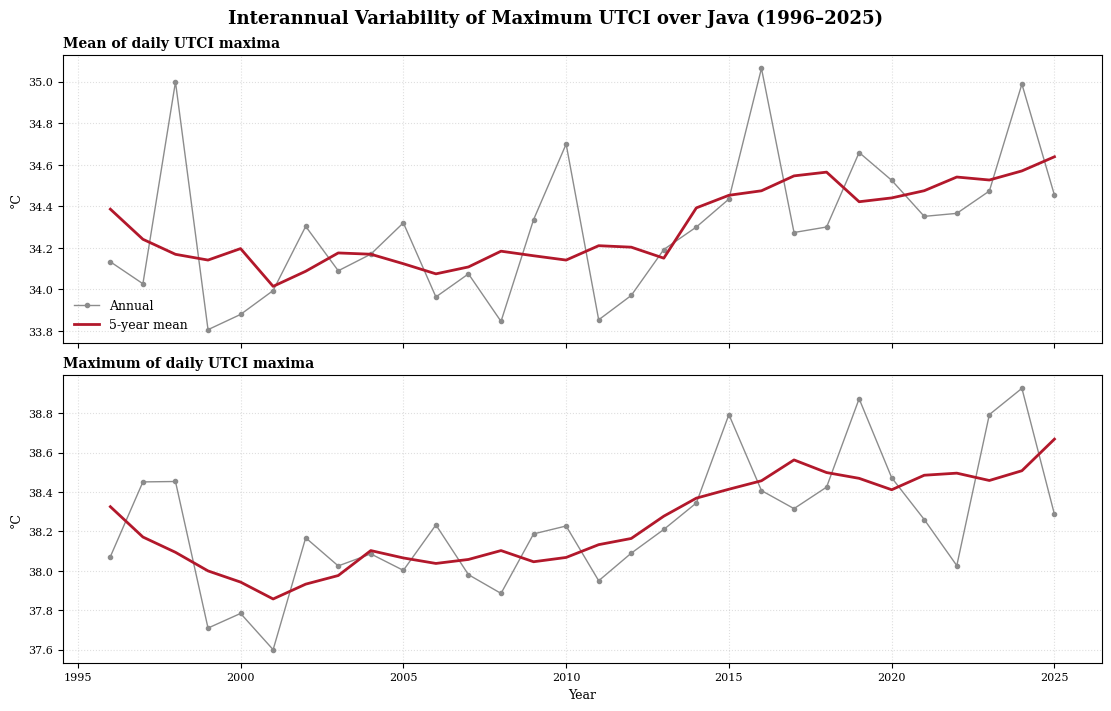

Disimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\Plot_UTCI_Jawa_PaperStyle\FIG04_UTCI_Jawa_Annual_Mean_Max_TimeSeries.png


In [6]:
fig,axs=plt.subplots(2,1,figsize=(11,7),sharex=True,constrained_layout=True)
for ax,key,title in zip(axs,['UTCI_mean','UTCI_max'],['Mean of daily UTCI maxima','Maximum of daily UTCI maxima']):
    y=np.array([area_mean(f,lat,valid_mask) for f in all_data[key]])
    ax.plot(years,y,'o-',ms=3,color='0.55',lw=1,label='Annual')
    ax.plot(years,pd.Series(y).rolling(5,center=True,min_periods=3).mean(),color='#b2182b',lw=2,label='5-year mean')
    ax.set_title(title,loc='left',weight='bold');ax.set_ylabel('°C');ax.grid(ls=':',alpha=.4)
axs[0].legend(frameon=False);axs[-1].set_xlabel('Year')
fig.suptitle('Interannual Variability of Maximum UTCI over Java (1996–2025)',weight='bold')
save_fig(fig,'FIG04_UTCI_Jawa_Annual_Mean_Max_TimeSeries',PLOT_DIR)

## 6. FIG 05 — peta fokus paparan termal ≥32 dan ≥38 °C

C:\Users\User\AppData\Local\Temp\ipykernel_3804\749150472.py:3: RuntimeWarning: Mean of empty slice
  maps=[np.nanmean(all_data[k],axis=0) for k in keys]


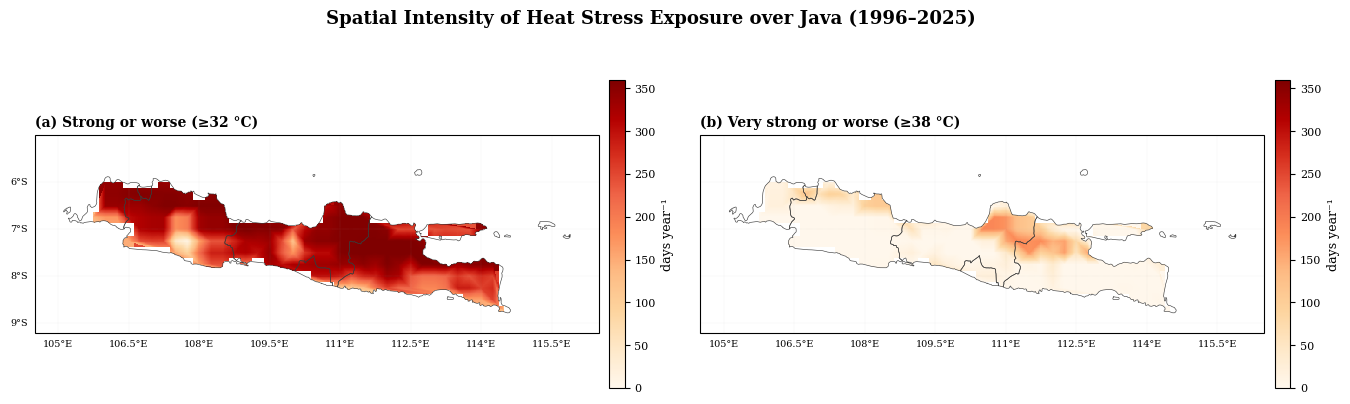

Disimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\Plot_UTCI_Jawa_PaperStyle\FIG05_UTCI_Jawa_Focused_Strong_VeryStrong_SMOOTH.png
✅ STEP 4 SELESAI → D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\Plot_UTCI_Jawa_PaperStyle


In [7]:
fig=plt.figure(figsize=(14,4.4));gs=fig.add_gridspec(1,2,wspace=.12,left=.06,right=.96,bottom=.12,top=.82)
keys=['StrongPlus_days','VeryStrongPlus_days'];titles=['Strong or worse (≥32 °C)','Very strong or worse (≥38 °C)']
maps=[np.nanmean(all_data[k],axis=0) for k in keys]
vmin,vmax=robust_limits(maps,zero_floor=True)
for i,(key,title) in enumerate(zip(keys,titles)):
    ax=fig.add_subplot(gs[0,i],projection=ccrs.PlateCarree())
    m=draw_field(ax,maps[i],lat,lon,valid_mask,cmap='OrRd',vmin=vmin,vmax=vmax)
    setup_map(ax,left=i==0,bottom=True);ax.set_title(f'({chr(97+i)}) {title}',weight='bold',loc='left')
    cb=fig.colorbar(m,ax=ax,fraction=.033,pad=.018);cb.set_label('days year⁻¹')
fig.suptitle('Spatial Intensity of Heat Stress Exposure over Java (1996–2025)',weight='bold')
save_fig(fig,'FIG05_UTCI_Jawa_Focused_Strong_VeryStrong_SMOOTH',PLOT_DIR)
print('✅ STEP 4 SELESAI →',PLOT_DIR)